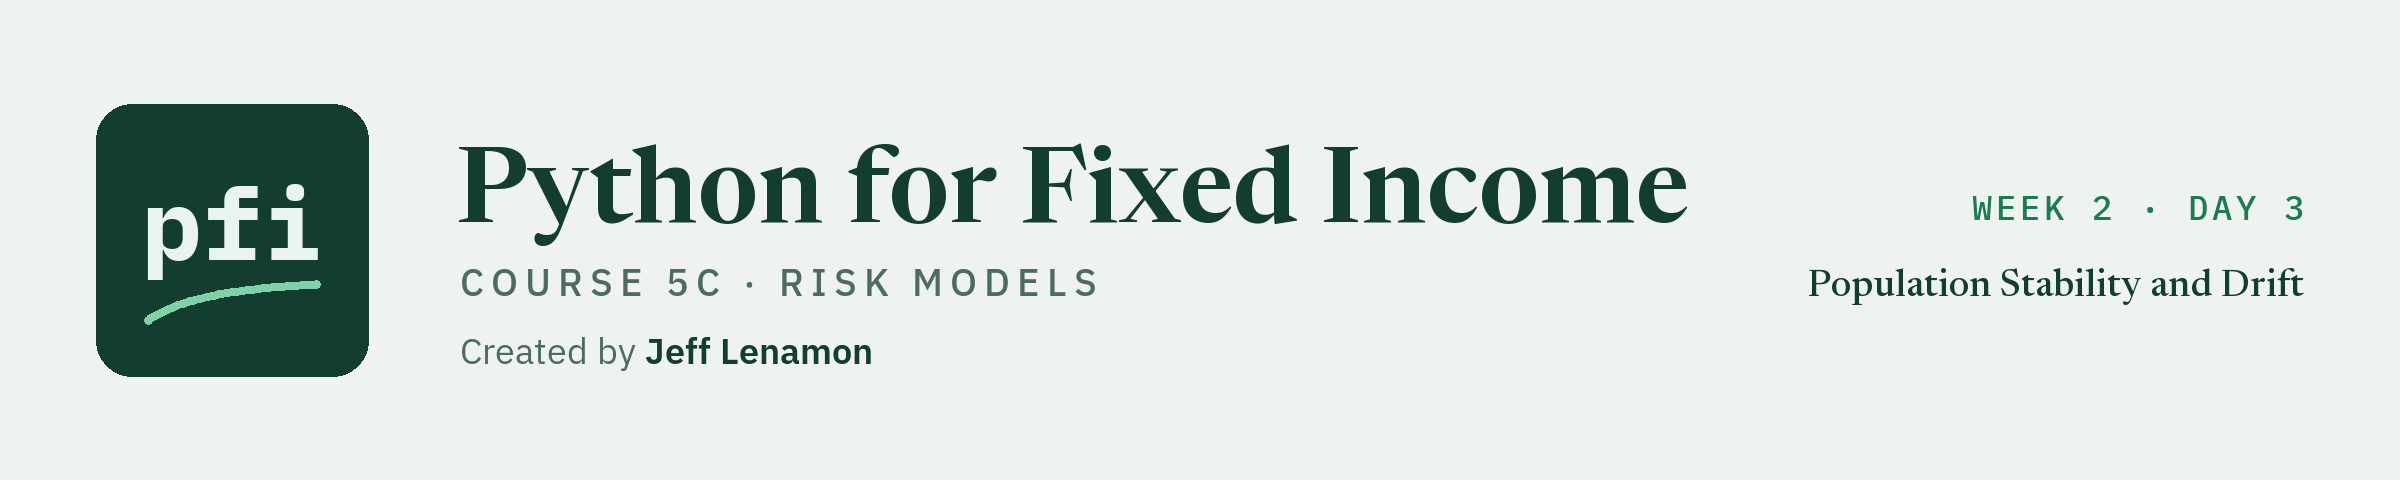

# Population Stability and Drift

Week 2, Day 3. Has the population moved? The population stability index by hand and by function, on the Treasury curve and on the cohort's entering firms, beside the KS test and Jensen-Shannon.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day3/08_population_stability_and_drift.ipynb)

Days 6 and 7 looked for one unusual row. Today's question is about a whole sample: has the population a model sees moved away from the one it was built on? The **population stability index** (PSI) answers it with one number. It cuts a reference sample into bins, counts the share of each sample in each bin, and adds up how far the shares have moved.

* **Two datasets.** The Treasury curve's development years (real, public domain): the 10 Yr's level and its daily change, 2019 to 2022 against 2015 to 2018. And the course's cohort (synthetic): the firms entering in study years 11 to 14 against those entering in 1 to 10.
* **The held-out years stay closed.** Every comparison today sits inside the development years; the held-out years are compared once, in the capstone.
* **The reference comes first.** The reference sample and its bin edges are fixed before the compared sample is read.
* **Drift is described.** A PSI says how far a sample sits from its reference. It is never a view of where a rate or a population goes next.

Today you will:

1. Compute a PSI by hand, then with `psi` (and `psi_edges`).
2. Set the 10 Yr level against its daily change.
3. Meet the empty bin and its floor.
4. Sweep the number of bins and the way they are cut.
5. Draw PSI quarter by quarter.
6. Find the cohort's planted shift with `psi_table`.
7. Set PSI beside the KS test and Jensen-Shannon, and see what each misses.

Q. Set up today's work folder: the thread settings, the seed, the curve, the cohort, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05c_risk_models/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scipy, statsmodels, or scikit-learn is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05c_risk_models/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5c_08_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course5c_cohort.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5c_08_0n_f33y1, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course5c_cohort.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, unchanged. `riskkit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `riskkit.py` and `test_riskkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile riskkit.py
"""riskkit: risk models for a bond desk, built day by day in Course 5C.

Conventions, stated once:
- Money is in US$. Rate and spread moves are in bp. A default probability is a fraction a year: 0.02 is 2 percent.
- A loss is a positive number of US$. P&L is positive for a gain.
- Every random draw comes from a numpy Generator the caller passes in as rng. Nothing here seeds a generator or
  uses the legacy np.random functions, so one seed at the top of a notebook decides every draw.
- The inputs are the course's synthetic book, its synthetic cohort, or past data. Nothing here describes a real
  security or a real issuer.
"""
import math

import numpy as np
from scipy.stats import norm

import mlkit  # noqa: F401  (the past-only checks, used from day 5)


def mc_mean(draws) -> tuple[float, float]:
    """The Monte Carlo estimate of a mean, and its standard error.

    Input: draws, a 1-D array of independent trial outcomes: at least 2, none of them NaN.
    Output: (mean, standard error). The standard error is the sample standard deviation (ddof=1) over the
    square root of the number of draws: how far the mean of this many draws typically lands from the true mean.
    Raises ValueError for fewer than 2 draws, more than one dimension, or a NaN.
    """
    values = np.asarray(draws, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("draws must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("draws hold a NaN")
    return float(values.mean()), float(values.std(ddof=1) / math.sqrt(len(values)))


def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
    """How many independent trials put a Monte Carlo mean within half_width of the true mean, at this confidence.

    n = ceil((z * sd / half_width) ** 2), with z the two-sided normal quantile (1.96 at 0.95).
    Inputs: sd, the standard deviation of one trial, and half_width, in the same unit, both above 0; confidence
    strictly between 0 and 1.
    Output: the number of trials, a whole number.
    Raises ValueError for an sd or half_width that is not above 0, or a confidence outside (0, 1).
    """
    if sd <= 0 or half_width <= 0:
        raise ValueError("sd and half_width must be above 0")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1")
    z = norm.ppf(0.5 + confidence / 2)
    return math.ceil((z * sd / half_width) ** 2)


def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
    """n standard normal draws in antithetic pairs: n // 2 draws z, then their mirror images -z.

    Inputs: rng, a numpy Generator; n, a positive even number.
    Output: an array of n draws. Draw i and draw i + n // 2 are a pair (z and -z), so the draws' mean is 0 exactly.
    A pair is not two independent draws: average each pair before computing a standard error.
    Raises ValueError for an n that is odd or not above 0.
    """
    if n <= 0 or n % 2:
        raise ValueError("n must be a positive even number")
    half = rng.standard_normal(n // 2)
    return np.concatenate([half, -half])


import pandas as pd  # dated tables: the book's P&L by day
from scipy.stats import chi2  # the chi-squared distribution of Kupiec's test


def historical_pnl(book, rate_moves, spread_moves):
    """The book's P&L on each past day, had that day's rate and spread moves happened to today's book.

    For each bond and day: the rate move is the Treasury change at the bond's years to maturity, read off the curve
    by straight-line interpolation between the two nearest tenors (the first or last tenor beyond the ends); the
    spread move is the bond's OAS times the relative change in its spread index (the DTS approach). The P&L is
    minus market value x (duration x rate move + spread duration x spread move) / 10,000. First order only: no
    convexity, no carry, no roll down the curve.
    Inputs:
    - book: a DataFrame with one row per bond and the columns market_value (US$), duration, spread_duration, oas
      (bp), years_to_maturity, and spread_index (the name of a column of spread_moves).
    - rate_moves: a DataFrame of daily Treasury changes in bp, one row per date, one column per tenor in years.
    - spread_moves: a DataFrame of daily relative changes of each spread index (0.01 is 1 percent wider), on the
      same dates as rate_moves.
    Output: a DataFrame on those dates with the columns rates, spreads, and total, in US$.
    Raises ValueError for a missing book column, an unknown spread index, dates that differ, or a NaN in the moves.
    """
    needed = ["market_value", "duration", "spread_duration", "oas", "years_to_maturity", "spread_index"]
    missing = [name for name in needed if name not in book.columns]
    if missing:
        raise ValueError(f"book lacks the columns {missing}")
    unknown = sorted(set(book["spread_index"]) - set(spread_moves.columns))
    if unknown:
        raise ValueError(f"spread_moves has no column for the spread indexes {unknown}")
    if not rate_moves.index.equals(spread_moves.index):
        raise ValueError("rate_moves and spread_moves must be on the same dates")
    if rate_moves.isna().any().any() or spread_moves[list(set(book["spread_index"]))].isna().any().any():
        raise ValueError("the moves hold a NaN")
    tenors = np.asarray(rate_moves.columns, dtype=float)
    # interpolation is linear in the curve's values, so each bond's weight on each tenor is the curve 0 everywhere
    # but 1 at that tenor, read at the bond's maturity
    weights = np.column_stack([np.interp(book["years_to_maturity"], tenors, np.eye(len(tenors))[j])
                               for j in range(len(tenors))])
    bond_rate_moves = rate_moves.to_numpy() @ weights.T
    bond_spread_moves = spread_moves[book["spread_index"]].to_numpy() * book["oas"].to_numpy()
    rates = -(bond_rate_moves * (book["duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    spreads = -(bond_spread_moves * (book["spread_duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    return pd.DataFrame({"rates": rates, "spreads": spreads, "total": rates + spreads}, index=rate_moves.index)


def var_es(pnl, level: float = 0.99) -> tuple[float, float]:
    """The VaR and the expected shortfall of a sample of P&L, both as positive US$ losses.

    VaR at level (for example 0.99) is minus the (1 - level) quantile of the P&L, with linear interpolation between
    the two nearest values: Excel's PERCENTILE.INC. Expected shortfall is minus the mean P&L on the days at or below
    that quantile: the average loss on the days the loss is at least the VaR, so it is never below the VaR.
    Inputs: pnl, a 1-D array of at least 2 values in US$, a gain positive, none of them NaN; level strictly between
    0.5 and 1.
    Output: (VaR, expected shortfall), in US$.
    Raises ValueError for fewer than 2 values, more than one dimension, a NaN, or a level outside (0.5, 1).
    """
    values = np.asarray(pnl, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("pnl must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("pnl holds a NaN")
    if not 0.5 < level < 1:
        raise ValueError("level must be between 0.5 and 1")
    cutoff = float(np.quantile(values, 1 - level))
    return -cutoff, -float(values[values <= cutoff].mean())


def kupiec_pof(exceptions: int, n: int, level: float) -> tuple[float, float]:
    """Kupiec's proportion-of-failures test: is the count of VaR exceptions in line with the VaR's level?

    Under a correct VaR each of n days is an exception with chance p = 1 - level, independently. The statistic is
    the likelihood ratio LR = -2 ln[(1 - p)^(n - x) p^x] + 2 ln[(1 - x/n)^(n - x) (x/n)^x] for x exceptions, which
    is close to a chi-squared with 1 degree of freedom when the VaR is right.
    Inputs: exceptions, a whole number from 0 to n; n, the number of days tested, above 0; level strictly between
    0 and 1.
    Output: (LR, p-value). A small p-value says the count is hard to square with the level: too many exceptions,
    or too few.
    Raises ValueError for a count outside 0 to n, an n that is not above 0, or a level outside (0, 1).
    """
    if n <= 0 or not 0 <= exceptions <= n:
        raise ValueError("exceptions must be between 0 and n, and n above 0")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    p, x = 1 - level, exceptions
    observed = x / n

    def log_likelihood(q: float) -> float:
        # x ln q + (n - x) ln(1 - q), with 0 ln 0 taken as 0
        return (x * math.log(q) if x else 0.0) + ((n - x) * math.log(1 - q) if n - x else 0.0)

    lr = max(0.0, -2 * (log_likelihood(p) - log_likelihood(observed)))
    return lr, float(chi2.sf(lr, 1))


def one_factor_defaults(pd, rho: float, n_sims: int, rng: np.random.Generator) -> np.ndarray:
    """Simulated defaults of a group of bonds whose defaults move together through one common factor.

    In each scenario every bond's asset value is sqrt(rho) x Z + sqrt(1 - rho) x e, with Z one standard normal draw
    shared by every bond (the state of the economy) and e a standard normal draw of the bond's own. A bond defaults
    when its asset value is below the normal quantile of its default probability, so each bond still defaults with
    exactly its own probability, and rho sets how often they default together.
    Inputs: pd, a number or a 1-D array of annual default probabilities, one per bond, each strictly between 0 and
    1; rho, the asset correlation, from 0 up to (not including) 1; n_sims, the number of scenarios, above 0; rng, a
    numpy Generator.
    Output: a boolean array of shape (n_sims, number of bonds): True where that bond defaulted in that scenario.
    Raises ValueError for a pd outside (0, 1), a rho outside [0, 1), or an n_sims that is not above 0.
    """
    probabilities = np.atleast_1d(np.asarray(pd, dtype=float))
    if probabilities.ndim != 1 or not ((probabilities > 0) & (probabilities < 1)).all():
        raise ValueError("pd must be a number or a 1-D array, each strictly between 0 and 1")
    if not 0 <= rho < 1:
        raise ValueError("rho must be from 0 up to 1")
    if n_sims <= 0:
        raise ValueError("n_sims must be above 0")
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(probabilities)))
    assets = math.sqrt(rho) * common + math.sqrt(1 - rho) * own
    return assets < norm.ppf(probabilities)


def vasicek_quantile(pd: float, rho: float, q: float) -> float:
    """The default rate of a very large group of alike bonds that is not exceeded with probability q (Vasicek).

    N((N^-1(pd) + sqrt(rho) x N^-1(q)) / sqrt(1 - rho)), N the standard normal distribution: the one-factor model's
    default rate when the common factor sits at its own q quantile on the bad side. Exact only in the limit of
    many bonds, each with the same pd and rho.
    Inputs: pd, rho, and q, each strictly between 0 and 1.
    Output: a default rate between 0 and 1.
    Raises ValueError for any input outside (0, 1).
    """
    for name, value in (("pd", pd), ("rho", rho), ("q", q)):
        if not 0 < value < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1")
    return float(norm.cdf((norm.ppf(pd) + math.sqrt(rho) * norm.ppf(q)) / math.sqrt(1 - rho)))


def loss_distribution(book, defaults, lgd) -> np.ndarray:
    """The credit loss of the book in each simulated scenario, in US$.

    A defaulted bond loses its market value (its exposure at default) times its loss given default; a bond that did
    not default loses nothing.
    Inputs: book, a DataFrame with a market_value column (US$), one row per bond; defaults, a boolean array of shape
    (scenarios, bonds), as one_factor_defaults returns; lgd, the loss given default as a share between 0 and 1: a
    number, one per bond, or one per scenario and bond.
    Output: an array of one loss per scenario, in US$ (positive is a loss).
    Raises ValueError for defaults whose number of columns is not the number of bonds, or an lgd outside [0, 1].
    """
    hits = np.asarray(defaults, dtype=bool)
    exposure = book["market_value"].to_numpy(dtype=float)
    if hits.ndim != 2 or hits.shape[1] != len(exposure):
        raise ValueError("defaults must have one column per bond of the book")
    shares = np.asarray(lgd, dtype=float)
    if ((shares < 0) | (shares > 1)).any():
        raise ValueError("lgd must be between 0 and 1")
    return (hits * shares * exposure).sum(axis=1)


def kaplan_meier(time, event):
    """The Kaplan-Meier survival curve of a group observed for different lengths of time.

    Each subject is followed for time periods and either has the event at the end (event 1: here, a default) or is
    censored (event 0): it left the study, or the study ended, with no event seen. At each distinct time t, the
    subjects at risk are those followed for at least t; the curve multiplies, from the first time to t, the share
    of those at risk that did not have the event: S(t) = product of (1 - events / at risk). A censored subject counts
    as at risk up to and including its last time, and is never counted as an event.
    Inputs: time, a 1-D array of observed lengths (years, for example), each above 0; event, a 1-D array of the same
    length holding 1 for an event and 0 for censored.
    Output: a DataFrame with one row per distinct time, in order, and the columns at_risk, events, censored, and
    survival (the share expected to be event-free past that time).
    Raises ValueError for arrays of different lengths, a time that is not above 0, a NaN, or an event other than 0
    or 1.
    """
    times = np.asarray(time, dtype=float)
    events = np.asarray(event, dtype=float)
    if times.ndim != 1 or times.shape != events.shape or len(times) == 0:
        raise ValueError("time and event must be 1-D arrays of the same length, not empty")
    if np.isnan(times).any() or np.isnan(events).any():
        raise ValueError("time or event holds a NaN")
    if (times <= 0).any():
        raise ValueError("every time must be above 0")
    if not np.isin(events, (0, 1)).all():
        raise ValueError("event must hold only 0 and 1")
    distinct = np.unique(times)
    at_risk = np.array([(times >= t).sum() for t in distinct])
    had_event = np.array([((times == t) & (events == 1)).sum() for t in distinct])
    censored = np.array([((times == t) & (events == 0)).sum() for t in distinct])
    survival = np.cumprod(1 - had_event / at_risk)
    return pd.DataFrame({"at_risk": at_risk, "events": had_event, "censored": censored, "survival": survival},
                        index=pd.Index(distinct, name="time"))


def person_period(cohort):
    """The firm-years at risk, checked and ready for a discrete-time hazard model: one row per firm and study year.

    A firm-year row covers one firm in one study year, with its covariates dated at the start of that year. This
    checks the rows make a clean history (no repeated year, no gap between a firm's years, nothing after a default
    or an exit) and adds three columns: event (1 in the year of default), log_coverage (the natural log of coverage,
    because the hazard moves with coverage's ratio, not its difference), and early_years (1 in years 2 to 4 since
    entry, the cohort's planted bump in the hazard).
    Input: cohort, a DataFrame with firm_id, study_year, years_since_entry, coverage, default, and exit.
    Output: a copy sorted by firm_id and study_year with the three columns added.
    Raises ValueError for a missing column, a coverage that is not above 0, a firm with a repeated or missing study
    year, or a firm with a row after its default or its exit.
    """
    needed = ["firm_id", "study_year", "years_since_entry", "coverage", "default", "exit"]
    missing = [name for name in needed if name not in cohort.columns]
    if missing:
        raise ValueError(f"cohort lacks the columns {missing}")
    if (cohort["coverage"] <= 0).any():
        raise ValueError("coverage must be above 0 to take its log")
    rows = cohort.sort_values(["firm_id", "study_year"]).reset_index(drop=True)
    by_firm = rows.groupby("firm_id")
    if (by_firm["study_year"].diff().dropna() != 1).any():
        raise ValueError("a firm has a repeated or missing study year")
    # a default or an exit must be the firm's last row: nothing after it
    ended = by_firm["default"].cumsum() + by_firm["exit"].cumsum()
    if ((ended - rows["default"] - rows["exit"]) > 0).any():
        raise ValueError("a firm has a row after its default or its exit")
    rows["event"] = rows["default"].astype(int)
    rows["log_coverage"] = np.log(rows["coverage"])
    rows["early_years"] = rows["years_since_entry"].between(2, 4).astype(int)
    return rows


def hazard_to_survival(hazards) -> np.ndarray:
    """A survival curve from a run of yearly hazards: the share still free of default after each year.

    Survival after year t is the product of (1 - hazard) over years 1 to t, the Kaplan-Meier product with a model's
    hazards in place of counted ones.
    Input: hazards, a 1-D array of yearly hazards, each from 0 to 1, in time order.
    Output: an array of the same length: survival after each year.
    Raises ValueError for an empty array, more than one dimension, a NaN, or a hazard outside [0, 1].
    """
    values = np.asarray(hazards, dtype=float)
    if values.ndim != 1 or len(values) == 0:
        raise ValueError("hazards must be a 1-D array of at least one value")
    if np.isnan(values).any() or ((values < 0) | (values > 1)).any():
        raise ValueError("every hazard must be from 0 to 1")
    return np.cumprod(1 - values)


def robust_z(x) -> np.ndarray:
    """The robust z-score of each value: its distance from the median in units of the scaled median absolute deviation.

    (x - median) / (1.4826 x MAD), MAD the median of the absolute distances from the median. The factor 1.4826 makes
    the scaled MAD equal the standard deviation for normal data, so a robust z-score reads like an ordinary one; the
    NIST/SEMATECH handbook's modified Z-score is the same number, written with 0.6745 = 1 / 1.4826. Unlike the mean
    and standard deviation, the median and MAD barely move when a few values are wild, so the values being hunted
    cannot hide themselves.
    Input: x, a 1-D array of at least 3 values, none of them NaN.
    Output: an array of robust z-scores, one per value.
    Raises ValueError for fewer than 3 values, a NaN, or a MAD of 0 (half the values or more are equal).
    """
    values = np.asarray(x, dtype=float)
    if values.ndim != 1 or len(values) < 3:
        raise ValueError("x must be a 1-D array of at least 3 values")
    if np.isnan(values).any():
        raise ValueError("x holds a NaN")
    median = np.median(values)
    mad = np.median(np.abs(values - median))
    if mad == 0:
        raise ValueError("the MAD is 0: half the values or more are equal, so no spread can be measured")
    return (values - median) / (1.4826 * mad)


def iqr_flags(x, k: float = 1.5) -> np.ndarray:
    """Tukey's fences: flag each value below Q1 - k x IQR or above Q3 + k x IQR.

    Q1 and Q3 are the 25th and 75th percentiles with linear interpolation (Excel's QUARTILE.INC), and the IQR is
    Q3 - Q1. k = 1.5 gives Tukey's inner fences, k = 3 his outer ones.
    Inputs: x, a 1-D array of at least 4 values, none of them NaN; k, above 0.
    Output: a boolean array, True where the value is outside the fences.
    Raises ValueError for fewer than 4 values, a NaN, or a k that is not above 0.
    """
    values = np.asarray(x, dtype=float)
    if values.ndim != 1 or len(values) < 4:
        raise ValueError("x must be a 1-D array of at least 4 values")
    if np.isnan(values).any():
        raise ValueError("x holds a NaN")
    if k <= 0:
        raise ValueError("k must be above 0")
    q1, q3 = np.quantile(values, [0.25, 0.75])
    spread = q3 - q1
    return (values < q1 - k * spread) | (values > q3 + k * spread)


def precision_recall_at(flags, labels) -> tuple[float, float]:
    """Precision and recall of a set of flags against known labels.

    Precision is the share of flagged rows that are labelled (how many flags were right); recall is the share of
    labelled rows that were flagged (how many of the real ones were found). The labels only score the flags: they
    must never choose a threshold.
    Inputs: flags and labels, 1-D arrays of the same length holding True or False (or 1 or 0); labels must hold at
    least one True.
    Output: (precision, recall). With no flag at all, precision is NaN: there is nothing to be right about.
    Raises ValueError for arrays of different lengths or labels with no True.
    """
    flagged = np.asarray(flags, dtype=bool)
    truth = np.asarray(labels, dtype=bool)
    if flagged.shape != truth.shape or flagged.ndim != 1:
        raise ValueError("flags and labels must be 1-D arrays of the same length")
    if not truth.any():
        raise ValueError("labels must hold at least one True")
    hits = int((flagged & truth).sum())
    precision = hits / flagged.sum() if flagged.any() else float("nan")
    return float(precision), hits / int(truth.sum())


from sklearn.covariance import MinCovDet  # the robust centre and covariance of the Mahalanobis screen


def mahalanobis_flags(frame, quantile: float = 0.999, random_state: int = 0):
    """Each row's robust Mahalanobis distance from the centre of the rows, and a flag where it is unusually far.

    The centre and covariance come from the minimum covariance determinant (scikit-learn's MinCovDet): the subset
    of rows whose covariance is smallest, so the unusual rows cannot pull the centre toward them or swell the spread
    (masking in several columns). The squared distance (x - centre)' S^-1 (x - centre) measures how far a row sits
    in units of the data's own spread and correlation; for normal data it follows a chi-squared distribution with
    one degree of freedom per column, and the flag is a distance above that distribution's `quantile`.
    Inputs: frame, a DataFrame of numeric columns, at least 2 columns and more rows than columns, no NaN; quantile
    strictly between 0 and 1; random_state, the seed of MinCovDet's random subsets.
    Output: a DataFrame on frame's index with the columns distance (squared) and flag.
    Raises ValueError for a NaN, fewer than 2 columns, too few rows, or a quantile outside (0, 1).
    """
    if frame.isna().any().any():
        raise ValueError("frame holds a NaN")
    rows, columns = frame.shape
    if columns < 2 or rows <= columns:
        raise ValueError("frame needs at least 2 columns and more rows than columns")
    if not 0 < quantile < 1:
        raise ValueError("quantile must be strictly between 0 and 1")
    robust = MinCovDet(random_state=random_state).fit(frame.to_numpy(dtype=float))
    distance = robust.mahalanobis(frame.to_numpy(dtype=float))
    cutoff = chi2.ppf(quantile, columns)
    return pd.DataFrame({"distance": distance, "flag": distance > cutoff}, index=frame.index)

Writing riskkit.py


In [5]:
%%writefile test_riskkit.py
"""Tests for riskkit.py. Small seeded arrays only; no data file is read."""
import math

import numpy as np
import pytest

import riskkit


def test_mc_mean_hand():
    # mean 2.5; sample standard deviation sqrt(5/3); standard error that over sqrt(4)
    mean, se = riskkit.mc_mean([1.0, 2.0, 3.0, 4.0])
    assert mean == 2.5
    assert se == pytest.approx(math.sqrt(5 / 3) / 2, rel=1e-12)


def test_mc_mean_refuses():
    with pytest.raises(ValueError, match="at least 2"):
        riskkit.mc_mean([1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.mc_mean([1.0, float("nan"), 3.0])


def test_mc_mean_covers_a_known_mean():
    # 2 percent default, US$600,000 lost: the true mean is US$12,000; 40,000 draws land within 4 standard errors
    rng = np.random.default_rng(42)
    losses = np.where(rng.random(40_000) < 0.02, 600_000.0, 0.0)
    mean, se = riskkit.mc_mean(losses)
    assert abs(mean - 12_000.0) < 4 * se


def test_trials_needed_hand():
    # z at 95 percent is 1.959964; (1.959964 * 10 / 1) ** 2 = 384.15, so 385 trials
    assert riskkit.trials_needed(10.0, 1.0) == 385
    # halving the half-width takes four times the trials, give or take the rounding up
    assert riskkit.trials_needed(10.0, 0.5) == 1_537
    with pytest.raises(ValueError, match="above 0"):
        riskkit.trials_needed(10.0, 0.0)
    with pytest.raises(ValueError, match="between 0 and 1"):
        riskkit.trials_needed(10.0, 1.0, confidence=1.0)


def test_antithetic_normals_pairs():
    draws = riskkit.antithetic_normals(np.random.default_rng(42), 10)
    assert len(draws) == 10
    assert np.array_equal(draws[5:], -draws[:5])
    assert draws.mean() == 0.0
    with pytest.raises(ValueError, match="even"):
        riskkit.antithetic_normals(np.random.default_rng(42), 7)


def test_antithetic_normals_same_seed_same_draws():
    first = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    second = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    assert np.array_equal(first, second)


import pandas as pd


def _one_bond(years):
    return pd.DataFrame({"market_value": [1_000_000.0], "duration": [5.0], "spread_duration": [5.0], "oas": [100.0],
                         "years_to_maturity": [years], "spread_index": ["ig"]})


def test_historical_pnl_hand():
    # 4 years sits halfway between the 3 and 5 year tenors: a 15 bp move, and 10 percent of 100 bp is 10 bp
    dates = pd.to_datetime(["2020-01-02"])
    rates = pd.DataFrame({3.0: [10.0], 5.0: [20.0]}, index=dates)
    spreads = pd.DataFrame({"ig": [0.10]}, index=dates)
    pnl = riskkit.historical_pnl(_one_bond(4.0), rates, spreads)
    assert pnl.loc[dates[0], "rates"] == pytest.approx(-7_500.0, rel=1e-12)
    assert pnl.loc[dates[0], "spreads"] == pytest.approx(-5_000.0, rel=1e-12)
    assert pnl.loc[dates[0], "total"] == pytest.approx(-12_500.0, rel=1e-12)
    # beyond the last tenor the last tenor's move is used
    assert riskkit.historical_pnl(_one_bond(8.0), rates, spreads).loc[dates[0], "rates"] == pytest.approx(-10_000.0)


def test_historical_pnl_refuses():
    dates = pd.to_datetime(["2020-01-02", "2020-01-03"])
    rates = pd.DataFrame({3.0: [10.0, 1.0], 5.0: [20.0, 2.0]}, index=dates)
    with pytest.raises(ValueError, match="same dates"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"ig": [0.1]}, index=dates[:1]))
    with pytest.raises(ValueError, match="no column"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"hy": [0.1, 0.2]}, index=dates))
    with pytest.raises(ValueError, match="NaN"):
        riskkit.historical_pnl(_one_bond(4.0), rates.where(rates > 1), pd.DataFrame({"ig": [0.1, 0.2]}, index=dates))


def test_var_es_hand():
    # losses of 1 to 100: the 5 percent quantile of the P&L sits 4.95 of the way from -100 to -99, so VaR 95.05;
    # the days at or below it lose 100, 99, 98, 97, and 96, an average of 98
    var, es = riskkit.var_es(-np.arange(1.0, 101.0), 0.95)
    assert var == pytest.approx(95.05, rel=1e-12)
    assert es == pytest.approx(98.0, rel=1e-12)


def test_var_es_shortfall_at_least_var():
    pnl = np.random.default_rng(42).standard_t(4, 5_000)
    for level in (0.95, 0.99):
        var, es = riskkit.var_es(pnl, level)
        assert es >= var > 0


def test_var_es_refuses():
    with pytest.raises(ValueError, match="NaN"):
        riskkit.var_es([1.0, float("nan"), -2.0])
    with pytest.raises(ValueError, match="between 0.5 and 1"):
        riskkit.var_es([1.0, -2.0, 3.0], 0.01)


def test_kupiec_pof_hand():
    # exactly the expected count: the statistic is 0 and the p-value 1
    assert riskkit.kupiec_pof(10, 1_000, 0.99) == pytest.approx((0.0, 1.0))
    # 5 exceptions in 250 days at 99 percent, against the formula written out
    x, n, p = 5, 250, 0.01
    lr = -2 * ((n - x) * math.log(1 - p) + x * math.log(p) - (n - x) * math.log(1 - x / n) - x * math.log(x / n))
    assert riskkit.kupiec_pof(x, n, 0.99)[0] == pytest.approx(lr, rel=1e-12)
    # no exception at all is too few for a long sample
    assert riskkit.kupiec_pof(0, 2_000, 0.99)[1] < 0.01


def test_kupiec_pof_refuses():
    with pytest.raises(ValueError, match="between 0 and n"):
        riskkit.kupiec_pof(11, 10, 0.99)


from scipy.stats import norm


def test_one_factor_defaults_shape_and_rate():
    defaults = riskkit.one_factor_defaults([0.02, 0.10], 0.3, 50_000, np.random.default_rng(42))
    assert defaults.shape == (50_000, 2) and defaults.dtype == bool
    # each bond still defaults with its own probability, whatever rho is
    assert defaults[:, 0].mean() == pytest.approx(0.02, abs=0.003)
    assert defaults[:, 1].mean() == pytest.approx(0.10, abs=0.006)


def test_one_factor_defaults_correlation_fattens_the_count():
    # 100 alike bonds: the mean count stays at 2, the chance of 10 or more grows with rho
    rng_a, rng_b = np.random.default_rng(42).spawn(2)
    independent = riskkit.one_factor_defaults(np.full(100, 0.02), 0.0, 20_000, rng_a).sum(axis=1)
    correlated = riskkit.one_factor_defaults(np.full(100, 0.02), 0.3, 20_000, rng_b).sum(axis=1)
    assert abs(independent.mean() - correlated.mean()) < 0.2
    assert (correlated >= 10).mean() > 10 * max((independent >= 10).mean(), 1e-4)


def test_one_factor_defaults_refuses():
    with pytest.raises(ValueError, match="strictly between 0 and 1"):
        riskkit.one_factor_defaults([0.02, 0.0], 0.2, 10, np.random.default_rng(42))
    with pytest.raises(ValueError, match="rho"):
        riskkit.one_factor_defaults(0.02, 1.0, 10, np.random.default_rng(42))


def test_vasicek_quantile_hand():
    # at q = 0.5 the common factor sits at 0: N(N^-1(pd) / sqrt(1 - rho))
    assert riskkit.vasicek_quantile(0.02, 0.2, 0.5) == pytest.approx(norm.cdf(norm.ppf(0.02) / math.sqrt(0.8)), rel=1e-12)
    # a rho near 0 gives back pd at any q
    assert riskkit.vasicek_quantile(0.02, 1e-12, 0.999) == pytest.approx(0.02, rel=1e-4)
    with pytest.raises(ValueError, match="rho"):
        riskkit.vasicek_quantile(0.02, 0.0, 0.999)


def test_loss_distribution_hand():
    book = pd.DataFrame({"market_value": [100.0, 200.0, 300.0]})
    defaults = np.array([[True, False, True], [False, False, False]])
    # scenario 1 loses 60 percent of 100 and of 300; scenario 2 loses nothing
    assert riskkit.loss_distribution(book, defaults, 0.6).tolist() == pytest.approx([240.0, 0.0])
    assert riskkit.loss_distribution(book, defaults, [0.5, 0.6, 0.7]).tolist() == pytest.approx([260.0, 0.0])
    with pytest.raises(ValueError, match="one column per bond"):
        riskkit.loss_distribution(book, defaults[:, :2], 0.6)


def test_kaplan_meier_hand():
    # six subjects: events at 1 and 3, censored at 2, 3, 4, and 4
    table = riskkit.kaplan_meier([1, 2, 3, 3, 4, 4], [1, 0, 1, 0, 0, 0])
    assert table.index.tolist() == [1.0, 2.0, 3.0, 4.0]
    assert table["at_risk"].tolist() == [6, 5, 4, 2]
    assert table["events"].tolist() == [1, 0, 1, 0]
    assert table["censored"].tolist() == [0, 1, 1, 2]
    # 5/6 after time 1, unchanged at 2 (a censoring is not an event), then times 3/4 at time 3
    assert table["survival"].tolist() == pytest.approx([5 / 6, 5 / 6, 5 / 6 * 3 / 4, 5 / 6 * 3 / 4])


def test_kaplan_meier_without_censoring_is_the_plain_share():
    # with no censoring, survival past t is simply the share still event-free
    time = np.array([1, 2, 2, 3, 5])
    table = riskkit.kaplan_meier(time, np.ones(5))
    assert table["survival"].tolist() == pytest.approx([0.8, 0.4, 0.2, 0.0])


def test_kaplan_meier_refuses():
    with pytest.raises(ValueError, match="same length"):
        riskkit.kaplan_meier([1, 2], [1])
    with pytest.raises(ValueError, match="above 0"):
        riskkit.kaplan_meier([0, 2], [1, 0])
    with pytest.raises(ValueError, match="only 0 and 1"):
        riskkit.kaplan_meier([1, 2], [1, 2])


def _firm_years():
    # two firms: F1 watched three years and defaults in its third; F2 watched two years, still at risk
    return pd.DataFrame({"firm_id": ["F2", "F1", "F1", "F2", "F1"], "study_year": [5, 3, 1, 6, 2],
                         "years_since_entry": [1, 3, 1, 2, 2], "coverage": [4.0, 1.0, 3.0, 5.0, 2.0],
                         "default": [0, 1, 0, 0, 0], "exit": [0, 0, 0, 0, 0]})


def test_person_period_hand():
    rows = riskkit.person_period(_firm_years())
    assert rows["firm_id"].tolist() == ["F1", "F1", "F1", "F2", "F2"]
    assert rows["study_year"].tolist() == [1, 2, 3, 5, 6]
    assert rows["event"].tolist() == [0, 0, 1, 0, 0]
    assert rows["early_years"].tolist() == [0, 1, 1, 0, 1]
    assert rows["log_coverage"].tolist() == pytest.approx(np.log([3.0, 2.0, 1.0, 4.0, 5.0]).tolist())


def test_person_period_refuses_a_broken_history():
    gap = _firm_years()
    gap.loc[2, "study_year"] = 0  # F1's first year becomes year 0: a gap before year 2
    with pytest.raises(ValueError, match="missing study year"):
        riskkit.person_period(gap)
    after = _firm_years()
    after.loc[4, "default"] = 1  # F1 now defaults in year 2 and still has a row in year 3
    with pytest.raises(ValueError, match="after its default"):
        riskkit.person_period(after)


def test_hazard_to_survival_hand():
    assert riskkit.hazard_to_survival([0.1, 0.2, 0.0]).tolist() == pytest.approx([0.9, 0.72, 0.72])
    with pytest.raises(ValueError, match="from 0 to 1"):
        riskkit.hazard_to_survival([0.1, 1.5])


def test_robust_z_hand():
    # median 3, absolute distances 2, 1, 0, 1, 97: MAD 1, so the robust z of 100 is 97 / 1.4826
    scores = riskkit.robust_z([1.0, 2.0, 3.0, 4.0, 100.0])
    assert scores.tolist() == pytest.approx([-2 / 1.4826, -1 / 1.4826, 0.0, 1 / 1.4826, 97 / 1.4826])
    with pytest.raises(ValueError, match="MAD is 0"):
        riskkit.robust_z([5.0, 5.0, 5.0, 9.0])


def test_robust_z_is_not_masked():
    # one wild value inflates the standard deviation so much that its own z-score stays modest
    values = np.append(np.random.default_rng(42).normal(0, 1, 30), 50.0)
    ordinary = (values - values.mean()) / values.std(ddof=1)
    assert abs(ordinary[-1]) < 6 < abs(riskkit.robust_z(values)[-1])


def test_iqr_flags_hand():
    # 1 to 8: quartiles 2.75 and 6.25 by linear interpolation, IQR 3.5, inner fences -2.5 and 11.5: nothing outside
    assert riskkit.iqr_flags([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]).tolist() == [False] * 8
    # add 30: quartiles 3 and 7, IQR 4, upper inner fence 13, so only 30 is flagged; the outer fence (k = 3) is 19
    values = [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 30.0]
    assert riskkit.iqr_flags(values).tolist() == [False] * 8 + [True]
    assert riskkit.iqr_flags(values, k=3).tolist() == [False] * 8 + [True]
    with pytest.raises(ValueError, match="above 0"):
        riskkit.iqr_flags(values, k=0)


def test_precision_recall_at_hand():
    flags = [True, True, False, True, False]
    labels = [True, False, False, True, True]
    # three flags, two right; three labelled rows, two found
    assert riskkit.precision_recall_at(flags, labels) == pytest.approx((2 / 3, 2 / 3))
    precision, recall = riskkit.precision_recall_at([False] * 5, labels)
    assert math.isnan(precision) and recall == 0.0
    with pytest.raises(ValueError, match="at least one True"):
        riskkit.precision_recall_at(flags, [False] * 5)


def test_mahalanobis_flags_finds_a_planted_row():
    # 500 correlated normal rows and one row that breaks the correlation without being extreme in either column
    rng = np.random.default_rng(42)
    common = rng.standard_normal(500)
    frame = pd.DataFrame({"a": common + 0.2 * rng.standard_normal(500), "b": common + 0.2 * rng.standard_normal(500)})
    frame.loc[500] = [2.0, -2.0]
    result = riskkit.mahalanobis_flags(frame, 0.999, random_state=42)
    assert result.loc[500, "flag"] and result["distance"].idxmax() == 500
    # neither column alone would flag it: each value is about 2 standard deviations
    assert abs(frame.loc[500, "a"] - frame["a"].median()) < 2.5 * frame["a"].std()
    # for normal rows the squared distance averages about one per column: about 2 here
    assert 1.5 < result["distance"].iloc[:500].mean() < 2.5


def test_mahalanobis_flags_refuses():
    frame = pd.DataFrame({"a": [1.0, 2.0, 3.0], "b": [1.0, 2.0, 4.0]})
    with pytest.raises(ValueError, match="more rows than columns"):
        riskkit.mahalanobis_flags(frame[["a"]])
    with pytest.raises(ValueError, match="quantile"):
        riskkit.mahalanobis_flags(pd.concat([frame] * 5, ignore_index=True), 1.0)

Writing test_riskkit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import riskkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(riskkit)

# the functions defined in riskkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(riskkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "riskkit" and not name.startswith("_")]
print(f"riskkit functions: {functions}")

riskkit functions: ['mc_mean', 'trials_needed', 'antithetic_normals', 'historical_pnl', 'var_es', 'kupiec_pof', 'one_factor_defaults', 'vasicek_quantile', 'loss_distribution', 'kaplan_meier', 'person_period', 'hazard_to_survival', 'robust_z', 'iqr_flags', 'precision_recall_at', 'mahalanobis_flags']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is the course's own. It writes `riskkit.py` and `test_riskkit.py` as day 7 left them.

## 8.1 PSI by Hand

**How it works.** Fix a **reference** sample, the population a model was built on, and cut it into bins at its own quantiles: with ten bins, each holds a tenth of the reference. Count the share of the **compared** sample in each of the same bins. For each bin, the term is (compared share - reference share) x ln(compared share / reference share); the PSI is the sum. Every term is zero or positive, because the difference and the log always have the same sign, so the PSI is 0 when the shares agree and grows as they move apart. The settings are the reference, the number of bins, how they are cut, and the floor for an empty bin (section 8.3). What comes out is one number per variable.

Q. Load the curve, and fix the reference before reading the compared sample.

In [9]:
# the Treasury curve's development years only: the held-out years stay closed until the capstone
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date").loc[:"2022-12-30"]
level = curve["10 Yr"]
# the 10 Yr's daily change in bp, rounded to whole bp: the file's yields have two decimals, and float arithmetic
# would otherwise leave 1.9999999 for 2
change = (level.diff() * 100).round(0).iloc[1:]

# the reference is fixed first: 2015 to 2018. The compared sample, 2019 to 2022, is read only after
reference_level, current_level = level.loc[:"2018-12-31"], level.loc["2019-01-01":]
reference_change, current_change = change.loc[:"2018-12-31"], change.loc["2019-01-01":]
print(f"10 Yr level: {len(reference_level):,} reference days, {len(current_level):,} compared days (percent)")
print(f"10 Yr daily change: {len(reference_change):,} reference days, {len(current_change):,} compared days (bp)")

10 Yr level: 1,000 reference days, 1,001 compared days (percent)
10 Yr daily change: 999 reference days, 1,001 compared days (bp)


Q. Compute the PSI of the 10 Yr level by hand: the edges, the shares, the terms, the sum.

In [10]:
# step 1: the bin edges, the reference's deciles, from the reference only
edges = np.quantile(reference_level, [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
# step 2: the share of each sample in each bin; a bin holds the values above its lower edge and up to its upper edge
reference_share = np.bincount(np.searchsorted(edges, reference_level, side="left"), minlength=10) / len(reference_level)
current_share = np.bincount(np.searchsorted(edges, current_level, side="left"), minlength=10) / len(current_level)
# step 3: one term per bin, then the sum
terms = (current_share - reference_share) * np.log(current_share / reference_share)
lower = np.concatenate([[-np.inf], edges])
upper = np.concatenate([edges, [np.inf]])
by_hand = pd.DataFrame({"from (percent)": lower, "to (percent)": upper, "reference share": reference_share,
                        "compared share": current_share, "term": terms},
                       index=pd.Index(range(1, 11), name="bin"))
psi_by_hand = terms.sum()
print(f"PSI of the 10 Yr level, 2019-2022 against 2015-2018, by hand: {psi_by_hand:.4f}")

PSI of the 10 Yr level, 2019-2022 against 2015-2018, by hand: 1.7173


In [11]:
plotkit.styled(by_hand, ["term"], "PSI by hand: the 10 Yr level, 2019-2022 against 2015-2018, in the reference's ten deciles",
               fmt="{:,.3f}")

,from (percent),to (percent),reference share,compared share,term
bin,,,,,
1,-inf,1.740,0.105,0.540,0.713
2,1.740,1.890,0.097,0.081,0.003
3,1.890,2.090,0.099,0.064,0.015
4,2.090,2.200,0.105,0.016,0.168
5,2.200,2.280,0.106,0.003,0.367
6,2.280,2.360,0.102,0.007,0.255
7,2.360,2.450,0.089,0.020,0.103
8,2.450,2.820,0.103,0.115,0.001
9,2.820,2.940,0.098,0.029,0.084


* Each reference share is close to a tenth (ties at a quantile move a few days from one bin to the next). The compared shares are not: 54% of the days of 2019 to 2022 sit in the lowest bin, below the reference's tenth percentile. Bin 1 carries the largest term.
* The first and last bins are open: a level below or above every reference day still lands in a bin.

Q. Add `psi_edges` and `psi` to `riskkit.py`. Read the docstrings first.

In [12]:
%%writefile -a riskkit.py


def psi_edges(reference, bins: int = 10):
    """The inner bin edges PSI uses: the reference's quantiles, from the reference only.

    Equal quantiles merge, and an edge at the reference's largest value is dropped (nothing in the reference lies
    above it), so a variable with few distinct values gets fewer than `bins` bins: len(edges) + 1 of them.
    Inputs: reference, a 1-D array of numbers, not empty; bins, a whole number of at least 2.
    Output: a sorted array of inner edges; the outer bins are open.
    """
    values = np.asarray(reference, dtype=float)
    inner = np.unique(np.quantile(values, np.linspace(0, 1, bins + 1)[1:-1]))
    return inner[inner < values.max()]


def psi(expected, actual, bins: int = 10, floor: float = 0.0001) -> float:
    """The population stability index of actual against expected: how far a sample has moved from a reference.

    The bin edges come from the reference (expected) only, at its quantiles (psi_edges), so the compared sample can
    never move them. The outer bins are open, so a value beyond the reference's range lands in an end bin. A bin holds
    the values above its lower edge and up to its upper edge, as Excel's FREQUENCY counts. A share of 0 is raised to
    `floor` before the log, so an empty bin gives a large finite term instead of infinity.
    PSI = sum over bins of (actual share - expected share) x ln(actual share / expected share): 0 when the shares agree.
    Inputs: expected and actual, 1-D arrays of numbers, neither empty, no NaN; bins, a whole number of at least 2;
    floor, strictly between 0 and 1.
    Output: the PSI, a number of at least 0.
    Raises ValueError for an empty array, a NaN, bins below 2, or a floor outside (0, 1).
    """
    reference = np.asarray(expected, dtype=float)
    compared = np.asarray(actual, dtype=float)
    if reference.size == 0 or compared.size == 0:
        raise ValueError("expected and actual must not be empty")
    if np.isnan(reference).any() or np.isnan(compared).any():
        raise ValueError("expected and actual must not hold a NaN")
    if bins < 2:
        raise ValueError("bins must be at least 2")
    if not 0 < floor < 1:
        raise ValueError("floor must be strictly between 0 and 1")
    inner = psi_edges(reference, bins)
    # side="left" puts a value equal to an edge in the bin below it, as FREQUENCY does
    reference_share = np.bincount(np.searchsorted(inner, reference, side="left"), minlength=len(inner) + 1) / reference.size
    compared_share = np.bincount(np.searchsorted(inner, compared, side="left"), minlength=len(inner) + 1) / compared.size
    reference_share = np.maximum(reference_share, floor)
    compared_share = np.maximum(compared_share, floor)
    return float(np.sum((compared_share - reference_share) * np.log(compared_share / reference_share)))

Appending to riskkit.py


* `psi_edges` is the reference's quantiles and nothing else: the compared sample is not an argument, so it cannot move them.
* `psi` raises an empty bin's share to a floor before the log. Section 8.3 shows why.

In [13]:
%%writefile -a test_riskkit.py


def test_psi_hand():
    # reference 0 to 9 cut at its median 4.5: shares 0.5 and 0.5; the compared sample has 3 of 4 below
    expected = np.arange(10.0)
    actual = np.array([1.0, 2.0, 3.0, 7.0])
    hand = (0.75 - 0.5) * math.log(0.75 / 0.5) + (0.25 - 0.5) * math.log(0.25 / 0.5)
    assert riskkit.psi(expected, actual, 2) == pytest.approx(hand, rel=1e-12)
    # the same sample against itself has a PSI of 0
    assert riskkit.psi(expected, expected, 5) == 0.0
    # every compared value beyond the reference's range: the floor keeps the answer finite
    assert math.isfinite(riskkit.psi(expected, np.full(20, 100.0), 4))


def test_psi_refuses():
    with pytest.raises(ValueError, match="empty"):
        riskkit.psi([], [1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.psi([1.0, float("nan")], [1.0])
    with pytest.raises(ValueError, match="bins"):
        riskkit.psi([1.0, 2.0], [1.0], 1)

Appending to test_riskkit.py


In [14]:
importlib.reload(riskkit)
print(f"psi in riskkit: {hasattr(riskkit, 'psi')}")

psi in riskkit: True


In [15]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................                                         [100%]
32 passed in 2.04s



* `32 passed`. The hand test is the formula on two bins: a reference of 0 to 9 cut at its median, and four compared values, three below it.

Q. Run `psi` on the level and on the daily change.

In [16]:
psi_level = riskkit.psi(reference_level, current_level)
psi_change = riskkit.psi(reference_change, current_change)
print(f"riskkit.psi, the 10 Yr level: {psi_level:.4f}; the same as by hand: {abs(psi_level - psi_by_hand) < 1e-12}")
print(f"riskkit.psi, the 10 Yr daily change: {psi_change:.4f}")

riskkit.psi, the 10 Yr level: 1.7173; the same as by hand: True
riskkit.psi, the 10 Yr daily change: 0.0408


* The function gives the hand answer, 1.717. The daily change gives 0.041.

## 8.2 The Level Against Its Change

**How it works.** A level wanders: the 10 Yr's yield in one stretch of years can sit in a range another stretch never visits. Its daily change does not wander the same way: most days move a few bp up or down, whatever the level. PSI sees the difference at once. A model fed the level meets inputs its reference never held; a model fed the change meets inputs much like the ones it was built on. The setting is which form of the variable is compared. What comes out is two PSIs, and a picture of why they differ.

Q. Draw the two samples of each, overlaid.

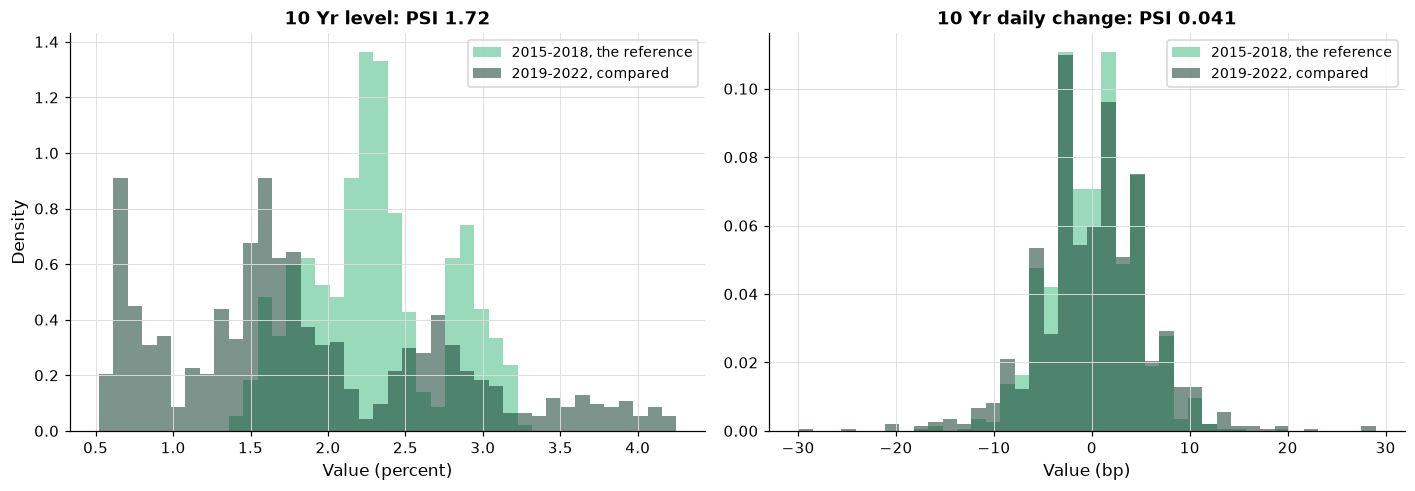

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, reference, current, unit, title in [(axes[0], reference_level, current_level, "percent", f"10 Yr level: PSI {psi_level:.2f}"),
                                            (axes[1], reference_change, current_change, "bp", f"10 Yr daily change: PSI {psi_change:.3f}")]:
    bins = np.histogram_bin_edges(np.concatenate([reference, current]), bins=40)
    ax.hist(reference, bins=bins, color=plotkit.GREEN_LIGHT, alpha=0.8, density=True, label="2015-2018, the reference")
    ax.hist(current, bins=bins, color=plotkit.GREEN_DARK, alpha=0.55, density=True, label="2019-2022, compared")
    ax.set_xlabel(f"Value ({unit})")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Density")
fig.tight_layout()
plt.show()

* How to read it: each panel overlays the two samples' histograms, scaled to the same area. On the left, 2015 to 2018 ran from 1.37 to 3.24 percent; 30% of the days of 2019 to 2022 sat below that range and 9% above it, and inside it their weight sits in other places. On the right the two are nearly the same shape. The PSI says the same in one number each.
* The daily changes are whole numbers of bp here, because the file's yields have two decimals, so the change's quantile edges are whole numbers too.

## 8.3 The Empty Bin and Its Floor

**How it works.** When a bin holds none of one sample, its share is 0, and ln(0) has no value: the term is infinite, and so is the PSI. A short compared sample makes this likely. The usual repair is a **floor**: a share below a small number is raised to it before the log. The PSI is then finite, but its size now depends on the floor chosen. The setting is the floor. What comes out is a finite PSI, to be read as "very large" rather than as an exact size.

Q. Take one quarter, January to March 2021, and compute its PSI against the same reference at several floors.

In [18]:
# one quarter, January to March 2021, against the same reference
quarter = level.loc["2021-01-01":"2021-03-31"]
quarter_share = np.bincount(np.searchsorted(riskkit.psi_edges(reference_level), quarter, side="left"), minlength=10) / len(quarter)
print(f"{len(quarter)} days; share in each reference bin: {np.round(quarter_share, 3)}")
# without a floor, an empty bin's term is (0 - 0.1) x ln(0 / 0.1): infinity
with np.errstate(divide="ignore"):
    print(f"the empty bins' terms without a floor: {(0 - 0.1) * np.log(0 / 0.1)}")
floors = [0.000001, 0.0001, 0.001, 0.01]
floor_sweep = pd.DataFrame({"PSI of the quarter": [riskkit.psi(reference_level, quarter, 10, f) for f in floors],
                            "PSI, 2019-2022": [riskkit.psi(reference_level, current_level, 10, f) for f in floors]},
                           index=pd.Index(floors, name="floor"))
print(floor_sweep.round(4).to_string())

61 days; share in each reference bin: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
the empty bins' terms without a floor: inf
          PSI of the quarter  PSI, 2019-2022
floor                                       
0.000001             12.3173          1.7173
0.000100              8.1895          1.7173
0.001000              6.0935          1.7173
0.010000              3.8675          1.5357


In [19]:
plotkit.styled(floor_sweep, [], "PSI against the floor: one quarter whose days all sit in one bin, and the full 2019-2022 sample",
               fmt="{:,.4f}")

,PSI of the quarter,"PSI, 2019-2022"
floor,,
1e-06,12.3173,1.7173
0.0001,8.1895,1.7173
0.001,6.0935,1.7173
0.01,3.8675,1.5357


* All 61 days of the quarter sit in the lowest bin; the other nine are empty. With a floor of 0.000001 the PSI is 12.32; with 0.01 it is 3.87. Neither number is the quarter's distance from the reference: both say "outside it".
* The full 2019 to 2022 sample has no empty bin. Its PSI is the same at the three smaller floors and changes only at 0.01, which is above its smallest share, 0.003. A floor matters where a bin is empty, and it should sit well below any real share.

## 8.4 Every Setting: How Many Bins, and How They Are Cut

**How it works.** PSI depends on the bins. **Quantile bins** each hold the same share of the reference; **equal-width bins** split the reference's range into equal steps, so the crowded middle and the thin tails get the same width. More bins see finer moves, and add noise: a bin that holds a few days moves a lot by chance. A variable with few distinct values cannot fill many quantile bins, because equal quantiles merge. The settings are the count and the method. What comes out is a table of PSIs for one pair of samples.

Q. Sweep 5, 10, 20, and 50 bins, both methods, for the level and the daily change.

In [20]:
def psi_from_edges(expected, actual, inner_edges, floor=0.0001):
    """PSI with the inner edges given, for comparing binning methods."""
    count = len(inner_edges) + 1
    e = np.maximum(np.bincount(np.searchsorted(inner_edges, expected, side="left"), minlength=count) / len(expected), floor)
    a = np.maximum(np.bincount(np.searchsorted(inner_edges, actual, side="left"), minlength=count) / len(actual), floor)
    return float(np.sum((a - e) * np.log(a / e)))


bin_rows = []
for name, reference, current in [("10 Yr level", reference_level, current_level), ("10 Yr daily change", reference_change, current_change)]:
    for bins in [5, 10, 20, 50]:
        # quantile bins (riskkit.psi) and equal-width bins between the reference's smallest and largest value
        equal_width = np.linspace(reference.min(), reference.max(), bins + 1)[1:-1]
        bin_rows.append({"series": name, "bins asked": bins, "quantile bins used": len(riskkit.psi_edges(reference, bins)) + 1,
                         "PSI, quantile bins": riskkit.psi(reference, current, bins),
                         "PSI, equal-width bins": psi_from_edges(reference, current, equal_width)})
bin_sweep = pd.DataFrame(bin_rows).set_index(["series", "bins asked"])
print(bin_sweep.round(3).to_string())

                               quantile bins used  PSI, quantile bins  PSI, equal-width bins
series             bins asked                                                               
10 Yr level        5                            5               1.218                  1.513
                   10                          10               1.717                  1.935
                   20                          20               2.025                  2.484
                   50                          50               2.585                  3.068
10 Yr daily change 5                            5               0.020                  0.063
                   10                          10               0.041                  0.080
                   20                          14               0.066                  0.108
                   50                          19               0.085                  0.147


In [21]:
plotkit.styled(bin_sweep, [], "PSI by number of bins and binning method, 2019-2022 against 2015-2018", fmt="{:,.3f}")

<styled table: PSI by number of bins and binning method, 2019-2022 against 2015-2018>

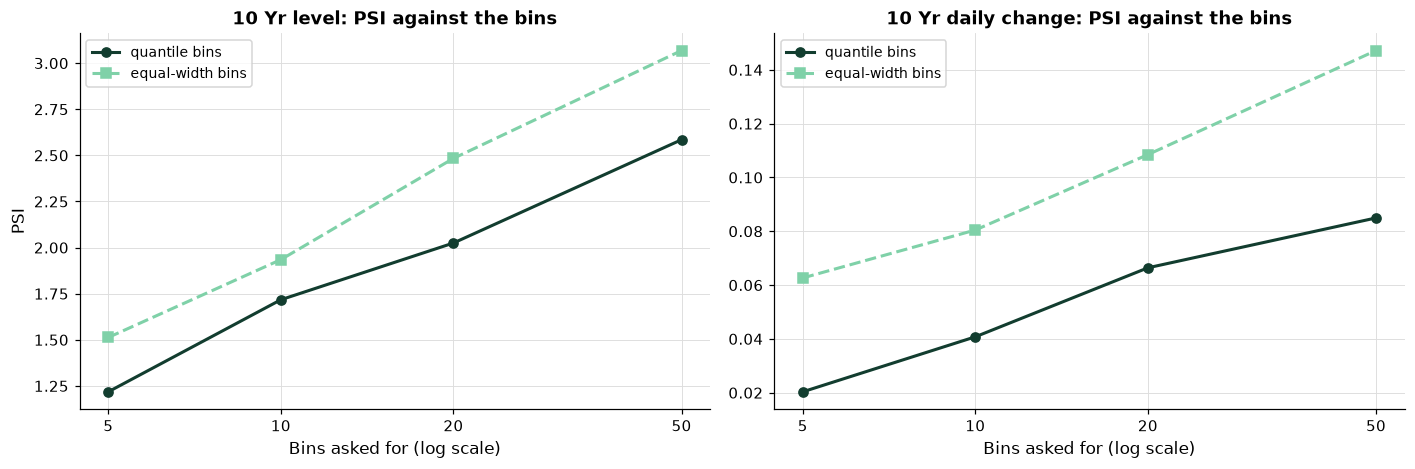

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, name in zip(axes, ["10 Yr level", "10 Yr daily change"]):
    part = bin_sweep.loc[name]
    ax.plot(part.index, part["PSI, quantile bins"], marker="o", color=plotkit.GREEN_DARK, linewidth=2, label="quantile bins")
    ax.plot(part.index, part["PSI, equal-width bins"], marker="s", color=plotkit.GREEN_LIGHT, linewidth=2, linestyle="--", label="equal-width bins")
    ax.set_xscale("log")
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xticks([5, 10, 20, 50])
    ax.set_xticklabels(["5", "10", "20", "50"])
    ax.set_xlabel("Bins asked for (log scale)")
    ax.set_title(f"{name}: PSI against the bins")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("PSI")
fig.tight_layout()
plt.show()

* How to read it: one panel per series, the PSI against the number of bins asked for. Every line climbs: here, more bins find more difference. The level's PSI runs from 1.22 at 5 bins to 2.58 at 50; the change's from 0.020 to 0.085.
* At 50 bins the daily change uses only 19 quantile bins: its values are whole numbers of bp, so many of the 49 quantiles fall on the same value and merge. Ten quantile bins is the common choice, and the one every other number today uses; whichever is chosen, it is fixed before any comparison, so a PSI is never compared with one computed on other bins.

## 8.5 PSI Quarter by Quarter

**How it works.** A monitor computes PSI again and again: each new window against the one fixed reference. The quarters that fall inside the reference period show what PSI looks like when nothing has moved; the quarters after it are judged against that. The settings are the window (a calendar quarter here) and the reference. What comes out is a line per variable.

Q. Compute the PSI of every quarter of 2015 to 2022, level and daily change, against the 2015-2018 reference.

In [23]:
# every calendar quarter of 2015 to 2022 against the fixed 2015-2018 reference
quarter_rows = []
for end, days in level.groupby(level.index.to_period("Q")):
    changes = change.loc[days.index.intersection(change.index)]
    quarter_rows.append({"quarter": str(end), "inside the reference": end <= pd.Period("2018Q4", freq="Q"),
                         "PSI, level": riskkit.psi(reference_level, days), "PSI, daily change": riskkit.psi(reference_change, changes)})
by_quarter = pd.DataFrame(quarter_rows).set_index("quarter")
inside = by_quarter[by_quarter["inside the reference"]]
after = by_quarter[~by_quarter["inside the reference"]]
print(f"{len(inside)} quarters inside the reference, {len(after)} after it")
print(f"median quarterly PSI of the daily change: inside {inside['PSI, daily change'].median():.3f}, after {after['PSI, daily change'].median():.3f}")
print(f"median quarterly PSI of the level: inside {inside['PSI, level'].median():.2f}, after {after['PSI, level'].median():.2f}")

16 quarters inside the reference, 16 after it
median quarterly PSI of the daily change: inside 0.217, after 0.183
median quarterly PSI of the level: inside 5.08, after 7.75


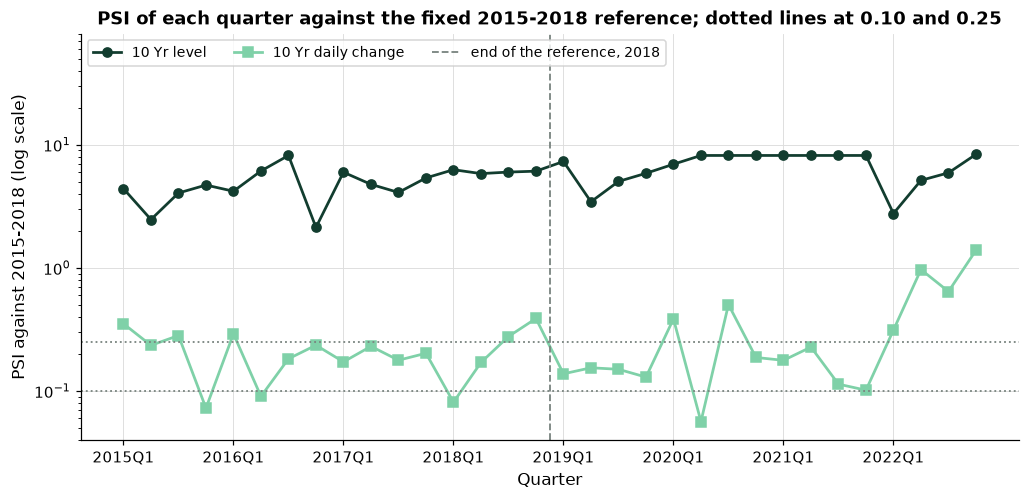

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.8))
positions = np.arange(len(by_quarter))
ax.plot(positions, by_quarter["PSI, level"], marker="o", color=plotkit.GREEN_DARK, linewidth=1.8, label="10 Yr level")
ax.plot(positions, by_quarter["PSI, daily change"], marker="s", color=plotkit.GREEN_LIGHT, linewidth=1.8, label="10 Yr daily change")
for value in (0.10, 0.25):
    ax.axhline(value, color=plotkit.GREY, linestyle=":", linewidth=1.2)
ax.axvline(len(inside) - 0.5, color=plotkit.GREY, linestyle="--", linewidth=1.2, label="end of the reference, 2018")
ax.set_yscale("log")
ax.set_ylim(0.04, 80)
ax.set_xticks(positions[::4])
ax.set_xticklabels(by_quarter.index[::4])
ax.set_xlabel("Quarter")
ax.set_ylabel("PSI against 2015-2018 (log scale)")
ax.set_title("PSI of each quarter against the fixed 2015-2018 reference; dotted lines at 0.10 and 0.25")
ax.legend(loc="upper left", fontsize=9, ncol=3)
plt.show()

* How to read it: one point per quarter, on a log scale. Left of the dashed line the quarters belong to the reference itself. A quarter is about 60 days spread over ten bins, so even there the daily change's PSI reaches 0.389 by chance (a median of 0.217). After 2018 most quarters sit in the same range (a median of 0.183); 2020Q3, 2022Q2, 2022Q3, 2022Q4 rise above anything inside the reference, from 0.50 to 1.39. The table describes those quarters' daily changes against 2015-2018 and nothing more.
* The level's quarterly PSI is high even inside the reference (a median of 5.08): a quarter of a wandering level covers a narrow slice of four years' range, so it never looks like the whole. 8 quarters sit at the same value, the PSI of a quarter whose days all fall in one bin at a floor of 0.0001 (section 8.3). A short window of a level is a poor sample of its reference; that is a property of the level, not a sign the reference is wrong.
* The dotted lines at 0.10 and 0.25 are the rules of thumb the story below reports, drawn for reading only.

## 8.6 Per-Feature PSI on the Cohort

**How it works.** A credit model reads several inputs, and each can drift on its own. **psi_table** computes the PSI of every input at once, each with its own reference bins, and sorts the table so the largest drift comes first. Here the population is the firms entering the synthetic cohort: those entering in study years 1 to 10 are the reference, those entering in 11 to 14 are compared. The cohort's generator shifts entering firms toward higher leverage and a lower rating from study year 11, written in `DATA.md`; the table should find it. The settings are the reference, the columns, and the bins. What comes out is one row per input.

Q. Load the cohort and fix the reference: the firms entering in study years 1 to 10.

In [25]:
# the synthetic cohort: invented firms, ids only; study years 15 to 20 stay closed until the capstone
cohort = pd.read_csv("course5c_cohort.csv")
entrants = cohort[(cohort["years_since_entry"] == 1) & (cohort["study_year"] <= 14)]
# the reference is fixed first: firms entering in study years 1 to 10. The compared sample: entering in 11 to 14
reference_firms = entrants[entrants["study_year"] <= 10]
current_firms = entrants[entrants["study_year"] >= 11]
print(f"{len(reference_firms):,} firms entering in study years 1 to 10; {len(current_firms):,} entering in 11 to 14")

2,508 firms entering in study years 1 to 10; 996 entering in 11 to 14


Q. Add `psi_table` to `riskkit.py`, with its test.

In [26]:
%%writefile -a riskkit.py


def psi_table(reference, current, columns, bins: int = 10):
    """PSI of each column of current against the same column of reference, one row per column.

    Each column's bins come from reference only (psi_edges). The table also shows the number of bins used, which is
    below `bins` for a column with few distinct values, and each sample's median.
    Inputs: reference and current, DataFrames that hold every name in columns as numbers; columns, a list of names.
    Output: a DataFrame indexed by column name with the columns psi, bins used, reference median, and current median,
    sorted by psi, largest first.
    Raises ValueError for an empty list of columns or a name missing from either DataFrame.
    """
    if len(columns) == 0:
        raise ValueError("columns must name at least one column")
    missing = [name for name in columns if name not in reference.columns or name not in current.columns]
    if missing:
        raise ValueError(f"columns missing from reference or current: {missing}")
    rows = []
    for name in columns:
        rows.append({"column": name, "psi": psi(reference[name], current[name], bins),
                     "bins used": len(psi_edges(reference[name], bins)) + 1,
                     "reference median": float(reference[name].median()), "current median": float(current[name].median())})
    return pd.DataFrame(rows).set_index("column").sort_values("psi", ascending=False)

Appending to riskkit.py


In [27]:
%%writefile -a test_riskkit.py


def test_psi_table_finds_the_shifted_column():
    rng = np.random.default_rng(42)
    reference = pd.DataFrame({"steady": rng.normal(0, 1, 2_000), "moved": rng.normal(0, 1, 2_000), "grade": rng.integers(1, 4, 2_000)})
    current = pd.DataFrame({"steady": rng.normal(0, 1, 2_000), "moved": rng.normal(0.5, 1, 2_000), "grade": rng.integers(1, 4, 2_000)})
    table = riskkit.psi_table(reference, current, ["steady", "moved", "grade"])
    assert table.index[0] == "moved" and table.loc["moved", "psi"] > 0.1 > table.loc["steady", "psi"]
    # a column with three distinct values uses three bins, not ten
    assert table.loc["grade", "bins used"] == 3
    with pytest.raises(ValueError, match="missing"):
        riskkit.psi_table(reference, current, ["absent"])

Appending to test_riskkit.py


In [28]:
importlib.reload(riskkit)
print(f"psi_table in riskkit: {hasattr(riskkit, 'psi_table')}")

psi_table in riskkit: True


In [29]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................................                                        [100%]
33 passed in 2.02s



* `33 passed`: day 7's 30 and today's 3. The table test plants a shift in one of three columns and checks it comes first, and that a column with three distinct values uses three bins.

Q. Compute the PSI of each input, then of each entry year against the same reference.

In [30]:
FEATURES = ["leverage", "coverage", "rating_score"]
drift = riskkit.psi_table(reference_firms, current_firms, FEATURES)
print(drift.round(3).to_string())

# each entry year against the same reference: the years inside it show what PSI is when nothing moved
by_year = pd.DataFrame({feature: [riskkit.psi(reference_firms[feature], entrants.loc[entrants["study_year"] == year, feature])
                                  for year in range(1, 15)] for feature in FEATURES},
                       index=pd.Index(range(1, 15), name="study year of entry"))
print(by_year.round(3).to_string())

                psi  bins used  reference median  current median
column                                                          
leverage      0.333         10             4.125           4.945
rating_score  0.232         10            10.000          12.000
coverage      0.122         10             5.855           4.720
                     leverage  coverage  rating_score
study year of entry                                  
1                       0.032     0.022         0.025
2                       0.025     0.017         0.036
3                       0.040     0.028         0.032
4                       0.019     0.041         0.045
5                       0.029     0.050         0.028
6                       0.020     0.038         0.027
7                       0.028     0.048         0.062
8                       0.033     0.025         0.041
9                       0.026     0.030         0.017
10                      0.056     0.034         0.031
11                      0.1

In [31]:
plotkit.styled(drift, ["psi"], "PSI of each input: firms entering in study years 11 to 14 against those entering in 1 to 10",
               fmt="{:,.3f}")

,psi,bins used,reference median,current median
column,,,,
leverage,0.333,10,4.125,4.945
rating_score,0.232,10,10.000,12.000
coverage,0.122,10,5.855,4.720


* Leverage has drifted most (0.333), then rating score (0.232), then coverage (0.122). The medians say which way: more leverage, a higher rating score (a lower rating), and less coverage.

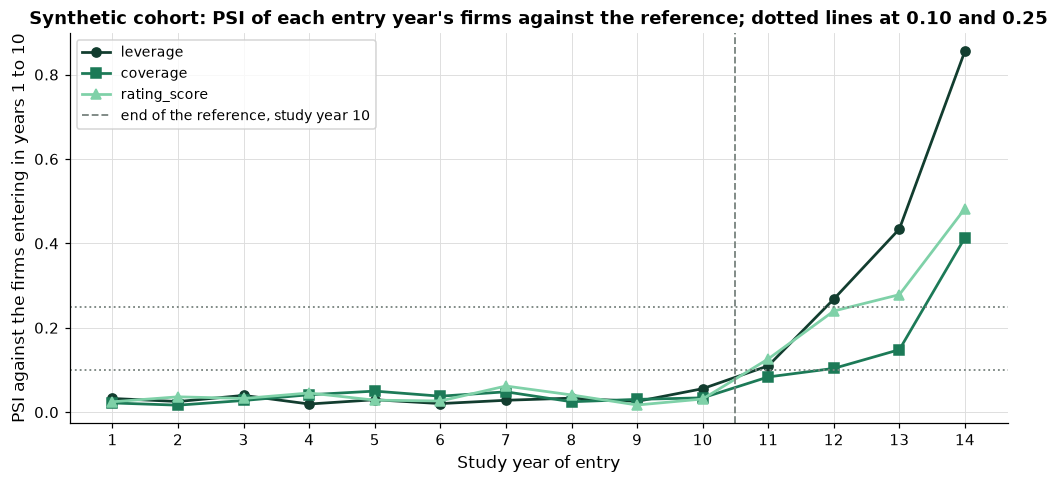

In [32]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for feature, colour, marker in zip(FEATURES, [plotkit.GREEN_DARK, plotkit.GREEN, plotkit.GREEN_LIGHT], ["o", "s", "^"]):
    ax.plot(by_year.index, by_year[feature], marker=marker, color=colour, linewidth=1.8, label=feature)
for value in (0.10, 0.25):
    ax.axhline(value, color=plotkit.GREY, linestyle=":", linewidth=1.2)
ax.axvline(10.5, color=plotkit.GREY, linestyle="--", linewidth=1.2, label="end of the reference, study year 10")
ax.set_xticks(range(1, 15))
ax.set_xlabel("Study year of entry")
ax.set_ylabel("PSI against the firms entering in years 1 to 10")
ax.set_title("Synthetic cohort: PSI of each entry year's firms against the reference; dotted lines at 0.10 and 0.25")
ax.legend(loc="upper left", fontsize=9)
plt.show()

* How to read it: one point per entry year and input. Years 1 to 10 are part of the reference, and their PSI stays below 0.062: about 250 firms a year is a small sample, and that is its noise. From year 11 the lines climb, leverage fastest, reaching 0.86 in year 14. The shift was planted, so the picture shows PSI finding a gradual move that a single pooled number would blur.

## 8.7 PSI, the KS Test, and Jensen-Shannon

**How it works.** Two other measures answer nearly the same question. The **Kolmogorov-Smirnov** (KS) statistic is the largest gap between the two samples' cumulative distributions, with no bins; its p-value tests whether the two could come from one population. The **Jensen-Shannon** distance compares the two samples' shares in the same bins as PSI, symmetrically, and in base 2 it runs from 0 to 1. The settings are the bins (PSI and Jensen-Shannon) and the sample sizes (the KS p-value). What comes out is one table, and what each measure misses.

Q. Compute all three for six comparisons.

In [33]:
from scipy.spatial.distance import jensenshannon
from scipy.stats import ks_2samp

def shares(sample, inner_edges):
    """The share of a sample in each bin of the given inner edges, with no floor."""
    return np.bincount(np.searchsorted(inner_edges, sample, side="left"), minlength=len(inner_edges) + 1) / len(sample)


pairs = [("10 Yr level, 2019-2022", reference_level, current_level), ("10 Yr daily change, 2019-2022", reference_change, current_change),
         ("10 Yr level, 2021 Q1", reference_level, quarter),
         ("leverage, entering 11-14", reference_firms["leverage"], current_firms["leverage"]),
         ("coverage, entering 11-14", reference_firms["coverage"], current_firms["coverage"]),
         ("rating score, entering 11-14", reference_firms["rating_score"], current_firms["rating_score"])]
compare_rows = []
for name, reference, current in pairs:
    inner = riskkit.psi_edges(reference)
    test = ks_2samp(reference, current)
    compare_rows.append({"comparison": name, "PSI": riskkit.psi(reference, current), "KS statistic": test.statistic,
                         "KS p-value": test.pvalue,
                         # Jensen-Shannon distance in base 2 on the same bins: 0 when the shares agree, 1 at most
                         "Jensen-Shannon": jensenshannon(shares(reference, inner), shares(current, inner), base=2)})
comparison = pd.DataFrame(compare_rows).set_index("comparison")
print(comparison.to_string(float_format=lambda v: f"{v:.3g}"))

                                 PSI  KS statistic  KS p-value  Jensen-Shannon
comparison                                                                    
10 Yr level, 2019-2022          1.72         0.437    9.56e-87           0.509
10 Yr daily change, 2019-2022 0.0408        0.0419        0.33          0.0856
10 Yr level, 2021 Q1            8.19         0.895    2.85e-54           0.866
leverage, entering 11-14       0.333         0.235    6.69e-35           0.241
coverage, entering 11-14       0.122         0.142     5.5e-13           0.147
rating score, entering 11-14   0.232         0.181    5.57e-21           0.202


In [34]:
plotkit.styled(comparison, [], "PSI, the KS test, and Jensen-Shannon distance on the same six comparisons", fmt="{:,.3g}")

,PSI,KS statistic,KS p-value,Jensen-Shannon
comparison,,,,
"10 Yr level, 2019-2022",1.72,0.437,9.56e-87,0.509
"10 Yr daily change, 2019-2022",0.0408,0.0419,0.33,0.0856
"10 Yr level, 2021 Q1",8.19,0.895,2.85e-54,0.866
"leverage, entering 11-14",0.333,0.235,6.69e-35,0.241
"coverage, entering 11-14",0.122,0.142,5.5e-13,0.147
"rating score, entering 11-14",0.232,0.181,5.57e-21,0.202


* **The KS p-value measures evidence, not size.** Coverage's PSI of 0.122 comes with a p-value of 5.5e-13, the level's 1.72 with 9.6e-87. With a thousand or more rows on each side, any shift a monitor would care about gives a p-value near zero, so the p-values cannot rank the drifts. The daily change's p-value of 0.33 says only that this much data cannot tell its two periods apart.
* **The KS statistic and Jensen-Shannon have a ceiling of 1.** For the 2021 quarter, whose days all sit in the reference's lowest bin, the KS statistic is 0.895 and Jensen-Shannon 0.866, close to that ceiling. PSI reads 8.19 there, but past that point its size is the floor's (section 8.3).
* **PSI misses nothing between the bins' edges and sees nothing inside a bin.** A sample can move within each bin and leave the PSI unchanged. The KS statistic, with no bins, would see it.

In [35]:
settings = pd.DataFrame([
    ("reference", "2015-2018 (curve); entering in years 1 to 10 (cohort)", "what the sample is compared with", "fixed before the compared sample is read"),
    ("bins", "10", "how finely the shares are counted", "riskkit.psi(expected, actual, bins)"),
    ("binning", "quantiles of the reference", "where the edges sit", "riskkit.psi_edges"),
    ("floor", "0.0001", "the share an empty bin is raised to", "riskkit.psi(..., floor)"),
    ("window", "a calendar quarter", "the compared sample in a monitor", "section 8.5"),
    ("thresholds", "none chosen; 0.10 and 0.25 drawn as reported rules of thumb", "how a PSI is read", "the story below"),
], columns=["setting", "today's choice", "what it controls", "where it is set"]).set_index("setting")
plotkit.styled(settings, [], "The settings of today's measures")

,today's choice,what it controls,where it is set
setting,,,
reference,2015-2018 (curve); entering in years 1 to 10 (cohort),what the sample is compared with,fixed before the compared sample is read
bins,10,how finely the shares are counted,"riskkit.psi(expected, actual, bins)"
binning,quantiles of the reference,where the edges sit,riskkit.psi_edges
floor,0.0001,the share an empty bin is raised to,"riskkit.psi(..., floor)"
window,a calendar quarter,the compared sample in a monitor,section 8.5
thresholds,none chosen; 0.10 and 0.25 drawn as reported rules of thumb,how a PSI is read,the story below


## A Story: Rules of Thumb Without Error Rates

In 2018 Bilal Yurdakul's doctoral dissertation in statistics at Western Michigan University, "Statistical Properties of Population Stability Index", set out to study a statistic that, in its abstract's words, "measures how much a variable has shifted over time". The abstract notes that "There are not many studies about the statistical properties of PSI". It reports the rules of thumb in use: a PSI below 0.10 means "little shift", and 0.25 marks "significant shift, action required". Then the point of the work: "these benchmarks are being used without reference to Type I or Type II error rates."

The point for a desk: a PSI threshold is a convention, and section 8.5 shows why it cannot be read blindly. A quarter of the 10 Yr level inside its own reference scores far above 0.25, and a quarter of its daily changes reaches 0.39 with nothing moved. How large a PSI is "large" depends on the variable and the sample size, which is what Yurdakul's error rates measure. This notebook draws the two lines and decides nothing with them.

Source: B. Yurdakul, "Statistical Properties of Population Stability Index", PhD dissertation, Western Michigan University, April 2018, the abstract, https://scholarworks.wmich.edu/dissertations/3208/ . The middle band of the rules of thumb does not display legibly on that page, so it is not quoted here.

## Excel Side by Side

Excel computes a PSI with three functions: `PERCENTILE.INC` for the edges, `FREQUENCY` for the counts, and `SUMPRODUCT` for the sum. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-24). The check pasted the 1,000 reference levels into A2:A1001, the 1,001 compared levels into B2:B1002, and the 61 levels of the 2021 quarter into C2:C62.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| The nine decile edges | `np.quantile(reference, [0.1, ..., 0.9])` | `=PERCENTILE.INC(A2:A1001,{0.1;0.2;0.3;0.4;0.5;0.6;0.7;0.8;0.9})` | 1.74 to 2.94 |
| The compared shares | `np.bincount(np.searchsorted(...)) / n` | `=FREQUENCY(B2:B1002,E2:E10)/COUNT(B2:B1002)` | first bin 0.540460 |
| The PSI | `riskkit.psi(reference, current)` | `=SUMPRODUCT((G2:G11-F2:F11)*LN(G2:G11/F2:F11))` | 1.717329 |
| A share with the floor | `np.maximum(share, 0.0001)` | `=IF(H2#<0.0001,0.0001,H2#)` | |
| The quarter's PSI | `riskkit.psi(reference, quarter)` | `=SUMPRODUCT((I2:I11-F2:F11)*LN(I2:I11/F2:F11))` | 8.189521 |

**The edges.** `PERCENTILE.INC` with an array of the nine deciles spills nine edges, reading the quantiles by straight line between values as numpy does by default.

**The shares.** `FREQUENCY(data, edges)` counts the values up to each edge and above the last one, ten counts from nine edges, which is why `psi` puts a value equal to an edge in the bin below it. Dividing by `COUNT` turns the counts into shares.

**The sum.** `SUMPRODUCT((G2:G11-F2:F11)*LN(G2:G11/F2:F11))` multiplies each bin's difference by its log ratio and adds the ten terms. For the quarter, nine bins are empty, so its shares go through `IF(...<0.0001,0.0001,...)` first; without it `LN(0)` returns `#NUM!`.

In [36]:
# Excel's results, from the course's Excel check, beside Python's
excel_side = pd.DataFrame({
    "Excel": [1.7173293118420832, 8.189520704292585, 0.5404595404595405],
    "Python": [psi_level, riskkit.psi(reference_level, quarter), by_hand.loc[1, "compared share"]],
}, index=pd.Index(["PSI of the 10 Yr level", "PSI of the 2021 quarter, floor 0.0001", "compared share, lowest bin"], name="Check"))
excel_side["equal within 1e-9"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-9
plotkit.styled(excel_side, [], "Excel beside Python on the PSI", fmt="{:,.6f}")

,Excel,Python,equal within 1e-9
Check,,,
PSI of the 10 Yr level,1.717329,1.717329,True
"PSI of the 2021 quarter, floor 0.0001",8.189521,8.189521,True
"compared share, lowest bin",0.540460,0.540460,True


* Every value is equal within 1e-9.

## Save the Day with Git

Today's Git step looks inside one commit. `git show --stat HEAD` prints the last commit's message and the files it changed, with a count of lines added: a quick check that a commit holds what its message says.

Q. Start a repository, commit the code, and look at what the commit holds.

In [37]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [38]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5c_08_0n_f33y1 and nowhere else


In [39]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [40]:
# show --stat: the commit's message and the files it changed
!git -C "{work}" add .gitignore mlkit.py riskkit.py test_riskkit.py
!git -C "{work}" commit -q -m "Day 8: riskkit with psi_edges, psi, and psi_table"
!git -C "{work}" show --stat --format=%s HEAD

Day 8: riskkit with psi_edges, psi, and psi_table

 .gitignore      |   3 +
 mlkit.py        | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 riskkit.py      | 467 ++++++++++++++++++++++++++++++++++++++++++++++
 test_riskkit.py | 323 ++++++++++++++++++++++++++++++++
 4 files changed, 1361 insertions(+)


## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `riskkit.py` and paste the code of today's two `riskkit.py` cells (sections 8.1 and 8.6) at the end, without their first lines. Do the same for the two `test_riskkit.py` cells in `test_riskkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_riskkit.py
```

The last line says `33 passed`.

**Step 4.** Commit, and check what the commit holds.

```powershell
git add riskkit.py test_riskkit.py
git commit -m "Day 8: riskkit with psi_edges, psi, and psi_table"
git show --stat HEAD
```

## You Can Now

* Compute a PSI by hand: reference bins, shares, terms, and the sum (`psi_edges`, `psi`).
* Say why a level drifts and its daily change barely does.
* Handle an empty bin with a floor, and read the result as "outside the reference".
* Sweep the bins and the way they are cut, and fix them before comparing.
* Draw PSI window by window against one fixed reference.
* Find which inputs drifted with `psi_table`.
* Set PSI beside the KS test and Jensen-Shannon, and say what each misses.

Next, day 9: a case study that monitors day 5's hazard model year by year, with every measure of this week.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the curve's development years and the cohort's entering firms, fixes the references as in the lesson, and defines `check`, a small function that marks your answers.

In [41]:
from scipy.stats import ks_2samp

# the Treasury curve's development years only: the held-out years stay closed until the capstone
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date").loc[:"2022-12-30"]
level = curve["10 Yr"]
# the 10 Yr's daily change in bp, rounded to whole bp: the file's yields have two decimals, and float arithmetic
# would otherwise leave 1.9999999 for 2
change = (level.diff() * 100).round(0).iloc[1:]

# the reference is fixed first: 2015 to 2018. The compared sample, 2019 to 2022, is read only after
reference_level, current_level = level.loc[:"2018-12-31"], level.loc["2019-01-01":]
reference_change, current_change = change.loc[:"2018-12-31"], change.loc["2019-01-01":]
print(f"10 Yr level: {len(reference_level):,} reference days, {len(current_level):,} compared days (percent)")
print(f"10 Yr daily change: {len(reference_change):,} reference days, {len(current_change):,} compared days (bp)")

# the synthetic cohort: invented firms, ids only; study years 15 to 20 stay closed until the capstone
cohort = pd.read_csv("course5c_cohort.csv")
entrants = cohort[(cohort["years_since_entry"] == 1) & (cohort["study_year"] <= 14)]
# the reference is fixed first: firms entering in study years 1 to 10. The compared sample: entering in 11 to 14
reference_firms = entrants[entrants["study_year"] <= 10]
current_firms = entrants[entrants["study_year"] >= 11]
print(f"{len(reference_firms):,} firms entering in study years 1 to 10; {len(current_firms):,} entering in 11 to 14")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

10 Yr level: 1,000 reference days, 1,001 compared days (percent)
10 Yr daily change: 999 reference days, 1,001 compared days (bp)


2,508 firms entering in study years 1 to 10; 996 entering in 11 to 14


### Exercise 1

Q. What is the PSI of the **2 Yr** level, 2019-2022 against 2015-2018, with `riskkit.psi` at its defaults? Store it in **ex1_psi**.

In [42]:
ex1_psi = ...

In [43]:
check("Exercise 1 PSI of the 2 Yr level", ex1_psi, 1.5967635907338118)

Exercise 1 PSI of the 2 Yr level: not attempted yet


### Exercise 2

Q. What is the PSI of the 10 Yr daily change with 20 bins instead of 10? Store it in **ex2_psi_20**.

In [44]:
ex2_psi_20 = ...

In [45]:
check("Exercise 2 PSI with 20 bins", ex2_psi_20, 0.06642188958802592)

Exercise 2 PSI with 20 bins: not attempted yet


### Exercise 3

Q. Add a function to your module. `psi_categories(expected, actual, floor=0.0001)` computes the PSI of a variable with categories, such as a sector: one bin per category seen in either sample, a missing category's share raised to the floor. It refuses an empty sample. Write the docstring first. Add `test_psi_categories_hand`, which checks shares of 0.5 and 0.5 against 0.75 and 0.25 by hand. Run pytest, reload the module, and store the PSI of the entering firms' `sector`, 11 to 14 against 1 to 10, in **ex3_sector**.

Write the function in the cell that starts with `%%writefile -a riskkit.py` and the test in the one that starts with `%%writefile -a test_riskkit.py`, and run each of those cells once.

In [46]:
%%writefile -a riskkit.py


# Exercise 3: write psi_categories(expected, actual, floor) below this line

Appending to riskkit.py


In [47]:
%%writefile -a test_riskkit.py


# Exercise 3: write test_psi_categories_hand() below this line

Appending to test_riskkit.py


In [48]:
# run pytest, reload the module, then use your function
ex3_sector = ...

In [49]:
check("Exercise 3 PSI of the sector", ex3_sector, 0.00900104374572795)

Exercise 3 PSI of the sector: not attempted yet


### Exercise 4

Q. What is the KS statistic of the entering firms' `coverage`, 11 to 14 against 1 to 10, from `ks_2samp`? Store it in **ex4_ks**, and compare it with the coverage row of section 8.6.

In [50]:
ex4_ks = ...

In [51]:
check("Exercise 4 KS statistic of coverage", ex4_ks, 0.14190734228781154)

Exercise 4 KS statistic of coverage: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a PSI function, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The population stability index of actual against expected, with ten quantile bins.

    The bin edges are the deciles of the reference sample, expected, and of nothing else: the compared sample must
    never move them. A share of 0 is raised to 0.0001 before the log.
    Returns sum over bins of (actual share - expected share) x ln(actual share / expected share).
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns one number, and contains one bug.

In [52]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def stability_index(expected, actual):
    """The population stability index of actual against expected, with ten quantile bins.

    The bin edges are the deciles of the reference sample, expected, and of nothing else: the compared sample must
    never move them. A share of 0 is raised to 0.0001 before the log.
    Returns sum over bins of (actual share - expected share) x ln(actual share / expected share).
    """
    expected = np.asarray(expected, dtype=float)
    actual = np.asarray(actual, dtype=float)
    edges = np.quantile(actual, np.linspace(0.1, 0.9, 9))
    expected_share = np.bincount(np.searchsorted(edges, expected, side="left"), minlength=10) / len(expected)
    actual_share = np.bincount(np.searchsorted(edges, actual, side="left"), minlength=10) / len(actual)
    expected_share, actual_share = np.maximum(expected_share, 0.0001), np.maximum(actual_share, 0.0001)
    return float(np.sum((actual_share - expected_share) * np.log(actual_share / expected_share)))

Q. Before you run the next cell: should this function give the same PSI as `riskkit.psi` on the 10 Yr level?

In [53]:
print(f"stability_index: {stability_index(reference_level, current_level):.4f}; riskkit.psi: {riskkit.psi(reference_level, current_level):.4f}")

stability_index: 2.5464; riskkit.psi: 1.7173


Q. Test the function against its docstring before you trust it: work one small case by hand from the reference's deciles, and compare.

In [54]:
# the test, written from the docstring before the code is trusted
# a case worked by hand from the docstring: the reference 1 to 100, and its lower half, 1 to 50
reference = np.arange(1.0, 101.0)
lower_half = np.arange(1.0, 51.0)
# the reference's deciles put 0.2 of the lower half in each of the first five bins and none in the last five
hand = 5 * (0.2 - 0.1) * np.log(0.2 / 0.1) + 5 * (0.0001 - 0.1) * np.log(0.0001 / 0.1)
result = stability_index(reference, lower_half)
assert abs(result - hand) < 1e-9, f"the PSI is {result:.4f}, not the {hand:.4f} worked by hand from the reference's deciles"
print(f"PSI {result:.4f}, the hand answer {hand:.4f}")

AssertionError: the PSI is 1.0791, not the 3.7970 worked by hand from the reference's deciles

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's PSI of the 10 Yr level, `stability_index(reference_level, current_level)`, in **ex5_psi**.

In [55]:
# fix the function above and run the test again, then store the answer
ex5_psi = ...

In [56]:
check("Exercise 5 PSI of the fixed function", ex5_psi, 1.7173293118420834)

Exercise 5 PSI of the fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```